In [3]:
import pandas as pd

df = pd.read_csv("student_placement_synthetic.csv")

print(df.head())
print(df.shape)
print(df.info())

     branch college_tier  cgpa  backlogs  coding_skills  dsa_score  \
0       ECE       Tier-3  6.70         0            7.6        4.4   
1  Chemical       Tier-2  5.70         0            5.4        7.9   
2        EE       Tier-2  7.19         0            5.6        6.8   
3        CE       Tier-2  6.48         0            5.2        3.1   
4       CSE       Tier-2  6.71         1            5.9        4.7   

   aptitude_score  communication_skills  ml_knowledge  system_design  \
0            49.5                   3.7           6.4            0.3   
1            72.0                   8.3           6.3            1.9   
2            79.1                   7.4           4.4            5.2   
3            48.4                   5.0           1.1            6.7   
4            61.2                   4.3           2.7            2.8   

   internships  projects_count  certifications  hackathons  \
0            1               4               4           3   
1            0        

In [4]:
print(df.isnull().sum())
print(df.describe())

branch                           0
college_tier                     0
cgpa                             0
backlogs                         0
coding_skills                    0
dsa_score                        0
aptitude_score                   0
communication_skills             0
ml_knowledge                     0
system_design                    0
internships                      0
projects_count                   0
certifications                   0
hackathons                       0
open_source_contributions        0
extracurriculars                 0
placement_status                 0
salary_package_lpa           31525
dtype: int64
                cgpa       backlogs  coding_skills      dsa_score  \
count  100000.000000  100000.000000  100000.000000  100000.000000   
mean        7.206381       0.547010       5.995147       5.500711   
std         0.925235       0.862727       1.496302       1.781961   
min         4.000000       0.000000       1.000000       1.000000   
25%         

In [5]:
df = df.drop(columns=["salary_package_lpa"], errors="ignore")

In [6]:
X = df.drop("placement_status", axis=1)
y = df["placement_status"]

In [7]:
print(X.select_dtypes(include="object").columns)

Index(['branch', 'college_tier'], dtype='str')


C:\Users\krish\AppData\Local\Temp\ipykernel_5848\2184100941.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include="object").columns)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical = X.select_dtypes(include="object").columns
numerical = X.select_dtypes(exclude="object").columns

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("num", "passthrough", numerical)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)


C:\Users\krish\AppData\Local\Temp\ipykernel_5848\874378334.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X.select_dtypes(include="object").columns


In [10]:
# ==========================================
# RANDOM FOREST MODEL
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Define categorical columns
categorical_cols = X.select_dtypes(include=["object", "string"]).columns

# Define numerical columns
numerical_cols = X.select_dtypes(exclude=["object", "string"]).columns

# Create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

# Create Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_predictions = rf_model.predict(X_test)

# Accuracy
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Accuracy (%):", rf_accuracy * 100)

# Classification report
print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 0.69255
Random Forest Accuracy (%): 69.255

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.19      0.28      6335
           1       0.71      0.93      0.80     13665

    accuracy                           0.69     20000
   macro avg       0.63      0.56      0.54     20000
weighted avg       0.66      0.69      0.64     20000



In [11]:
# ==========================================
# MODEL COMPARISON
# ==========================================

logistic_accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", logistic_accuracy * 100, "%")
print("Random Forest Accuracy:", rf_accuracy * 100, "%")

if logistic_accuracy > rf_accuracy:
    best_model = model
    best_model_name = "Logistic Regression"
    best_accuracy = logistic_accuracy
else:
    best_model = rf_model
    best_model_name = "Random Forest"
    best_accuracy = rf_accuracy

print("\n==============================")
print("BEST MODEL:", best_model_name)
print("BEST ACCURACY:", best_accuracy * 100, "%")
print("==============================")

Logistic Regression Accuracy: 69.905 %
Random Forest Accuracy: 69.255 %

BEST MODEL: Logistic Regression
BEST ACCURACY: 69.905 %


In [12]:
y_pred = model.predict(X_test)

In [13]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.69905


In [14]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.57      0.20      0.30      6335
           1       0.72      0.93      0.81     13665

    accuracy                           0.70     20000
   macro avg       0.64      0.57      0.55     20000
weighted avg       0.67      0.70      0.65     20000



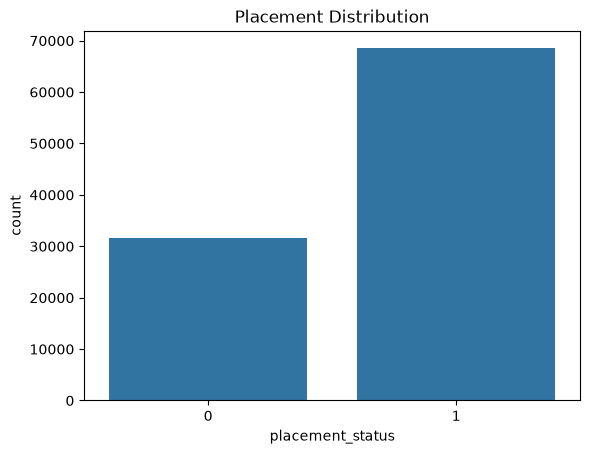

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x=df["placement_status"])
plt.title("Placement Distribution")
plt.show()

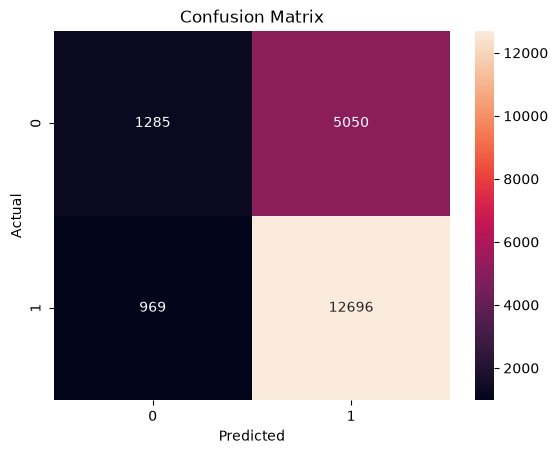

In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [17]:
import joblib

joblib.dump(model, "model/placement_model.pkl")


['model/placement_model.pkl']